# Day 2: Supervised learning on housing affordability

**Group 8** · IAAC MaAI 2026–27 · AI Methods · Day 2

Builds on the Day 1 output `data/housing_affordability_model_ready.csv` (1,210 rows × 29 columns, one row = one country in one year, 1977–2024).

**Task:** predict **next year's affordability** (`affordability_next`) for a country, from what is known this year.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

# works whether the notebook is run from the repo root or from notebook/
csv_name = "housing_affordability_model_ready.csv"
data_dir = Path("data") if (Path("data") / csv_name).exists() else Path("../data")
df = pd.read_csv(data_dir / csv_name)
print(df.shape)
df.head()

(1210, 29)


,affordability_next,iso,year,decade,affordability,real_house_price_index,real_personal_disposable_income,real_hpi_change_pct,real_income_change_pct,affordability_lag1,...,region_Africa,region_Asia,region_Central/Eastern Europe,region_Latin America,region_Middle East,region_Nordic,region_North America,region_Oceania,region_Southern Europe,region_Western Europe
0,38.061170,AUS,1977,1970,39.048834,21.43,54.88,-1.016166,-0.290698,39.335029,...,0,0,0,0,0,0,0,1,0,0
1,38.880944,AUS,1978,1970,38.061170,21.28,55.91,-0.699953,1.876822,39.048834,...,0,0,0,0,0,0,0,1,0,0
2,42.938456,AUS,1979,1970,38.880944,21.75,55.94,2.208647,0.053658,38.061170,...,0,0,0,0,0,0,0,1,0,0
3,44.351318,AUS,1980,1980,42.938456,24.14,56.22,10.988506,0.500536,38.880944,...,0,0,0,0,0,0,0,1,0,0
4,41.449879,AUS,1981,1980,44.351318,25.40,57.27,5.219553,1.867663,42.938456,...,0,0,0,0,0,0,0,1,0,0


# 1. Core concepts

## 1.1 Train / test split

A model evaluated on the data it learned from looks great, because it may simply have **memorised** the answers. We can only measure learning on rows it has **not seen**. So before anything else we **split** the data:

- **Training set** (~80%): the model learns from it.
- **Test set** (~20%): locked away and used **once, at the very end**, to estimate performance on new data.

**Why we do not shuffle.** `train_test_split` shuffles rows randomly. For our data that would be a form of leakage (see README §8.2): neighbouring years of the same country are almost identical, so training on 2014 and 2016 and testing on 2015 lets the model "see the future". Our real use case is forecasting, so we split **by time**:

- **Train:** 1977–2014
- **Test:** 2015–2024 (10 years × 26 countries = 260 rows, ≈ 21%)

The cut is on a year boundary, so all 26 countries of a given year are always on the same side. **We keep this split for the whole notebook.**

### Target: log10 of next year's affordability

`affordability_next` is strongly right-skewed: most values are around 100, but South Korea in the late 1970s–early 1980s reaches above 550 (skewness ≈ 5.4). On a log scale the distribution is much closer to a bell curve (skewness ≈ 0.9), so we predict **`log10(affordability_next)`**. A prediction is turned back into an affordability value with `10 ** y_pred`.

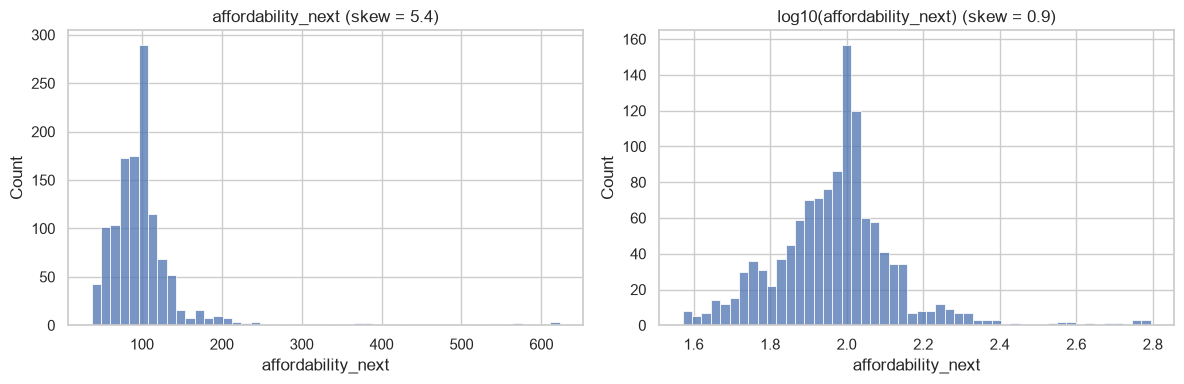

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["affordability_next"], bins=50, ax=axes[0])
axes[0].set_title(f"affordability_next (skew = {df['affordability_next'].skew():.1f})")
sns.histplot(np.log10(df["affordability_next"]), bins=50, ax=axes[1])
axes[1].set_title(f"log10(affordability_next) (skew = {np.log10(df['affordability_next']).skew():.1f})")
plt.tight_layout()
plt.show()

### Inputs: remove what must not be used

We drop from the inputs:
- `affordability_next`: the **target** itself (using it as an input would be the ultimate leak).
- `iso`: a country **identifier**, not a measurement (text, and it would let the model memorise countries).
- `data_reliable`, `is_latest_year`: **constant** in the model-ready file (always 1 and 0 after Day 1 filtering), so they carry no information.

The two leaking features from Day 1 (`affordability_vs_own_avg`, `affordability_position`) were already removed from this file. More on leakage in 1.5.

In [3]:
TARGET = "affordability_next"
drop_cols = [TARGET, "iso", "data_reliable", "is_latest_year"]

X = df.drop(columns=drop_cols)
y = np.log10(df[TARGET])

# time-based split: train up to 2014, test from 2015
SPLIT_YEAR = 2015
is_train = df["year"] < SPLIT_YEAR

X_train, X_test = X[is_train], X[~is_train]
y_train, y_test = y[is_train], y[~is_train]

print(f"Features: {X.shape[1]}")
print(f"Train: {len(X_train)} rows ({len(X_train) / len(X):.0%}), years {df.loc[is_train, 'year'].min()}–{df.loc[is_train, 'year'].max()}")
print(f"Test:  {len(X_test)} rows ({len(X_test) / len(X):.0%}), years {df.loc[~is_train, 'year'].min()}–{df.loc[~is_train, 'year'].max()}")

Features: 25
Train: 950 rows (79%), years 1977–2014
Test:  260 rows (21%), years 2015–2024


In [4]:
# sanity checks: no overlap in time, every country in both sets
assert df.loc[is_train, "year"].max() < df.loc[~is_train, "year"].min()
assert set(df.loc[is_train, "iso"]) == set(df.loc[~is_train, "iso"])
X.columns.tolist()

['year',
 'decade',
 'affordability',
 'real_house_price_index',
 'real_personal_disposable_income',
 'real_hpi_change_pct',
 'real_income_change_pct',
 'affordability_lag1',
 'affordability_lag2',
 'affordability_3yr_avg',
 'nominal_zero',
 'hyperinflation_country',
 'price_shock_up',
 'price_shock_down',
 'gfc_period',
 'region_Africa',
 'region_Asia',
 'region_Central/Eastern Europe',
 'region_Latin America',
 'region_Middle East',
 'region_Nordic',
 'region_North America',
 'region_Oceania',
 'region_Southern Europe',
 'region_Western Europe']

## 1.2 Underfitting and overfitting

A model can fail in two opposite ways:

| | **Underfitting** | **Good fit** | **Overfitting** |
|---|---|---|---|
| What happens | The model is too **simple** to capture the pattern | Captures the pattern, ignores the noise | The model is too **complex**: it memorises the noise |
| Training error | High | Low | **Very low** |
| Test error | High | Low | **High** |
| Analogy | A student who only learned "the answer is usually C" | A student who understood the subject | A student who memorised last year's exam |

### Synthetic example: window-to-wall ratio vs energy demand

We invent a "true" relation between the **window-to-wall ratio** (WWR) of a façade and its **energy demand**: too few windows means more artificial lighting, too many means more heat loss and overheating, so the curve is U-shaped with an optimum around 35%. We add random noise (like measurement errors), then fit three polynomial curves of increasing complexity on the training points (dark) and check them on the test points (orange).

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import root_mean_squared_error

rng = np.random.default_rng(42)

def true_demand(wwr):
    # kWh/m²/year: minimum around 35% WWR
    return 90 + 400 * (wwr - 0.35) ** 2

wwr = rng.uniform(0.05, 0.90, 40)
demand = true_demand(wwr) + rng.normal(0, 8, wwr.size)

# synthetic data has no time order, so a random split is fine here
wwr_train, wwr_test, dem_train, dem_test = train_test_split(
    wwr, demand, test_size=0.3, random_state=42)
print(len(wwr_train), "train points,", len(wwr_test), "test points")

28 train points, 12 test points


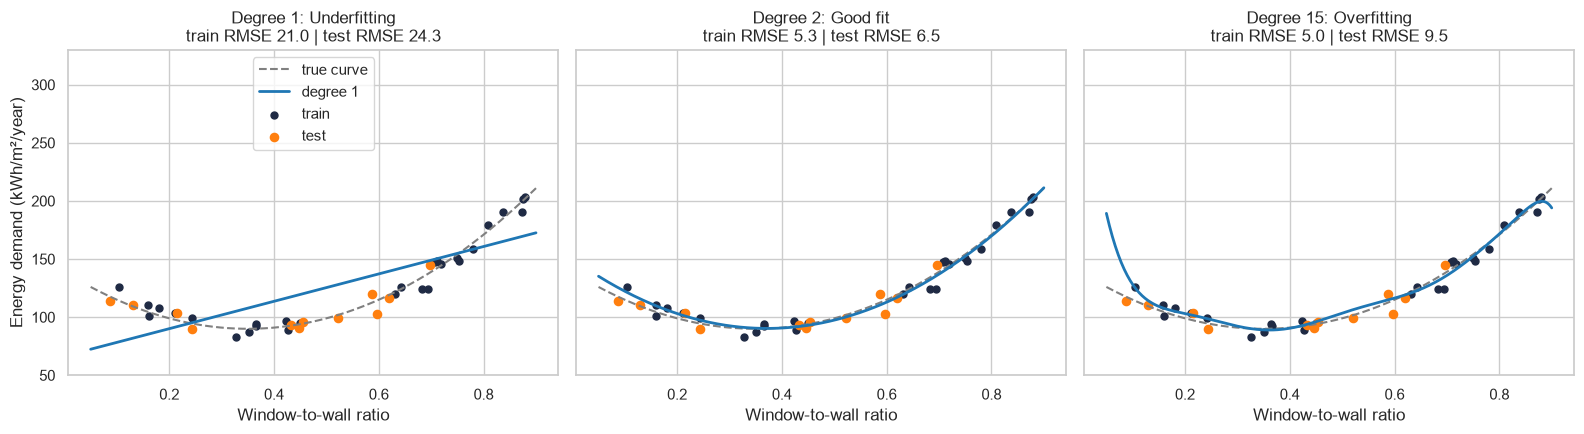

,degree,fit,train RMSE,test RMSE
0,1,Underfitting,21.0,24.3
1,2,Good fit,5.3,6.5
2,15,Overfitting,5.0,9.5


In [6]:
degrees = {1: "Underfitting", 2: "Good fit", 15: "Overfitting"}
grid = np.linspace(0.05, 0.90, 300)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
rows = []
for ax, (deg, label) in zip(axes, degrees.items()):
    model = make_pipeline(PolynomialFeatures(deg), StandardScaler(), LinearRegression())
    model.fit(wwr_train.reshape(-1, 1), dem_train)

    rmse_train = root_mean_squared_error(dem_train, model.predict(wwr_train.reshape(-1, 1)))
    rmse_test = root_mean_squared_error(dem_test, model.predict(wwr_test.reshape(-1, 1)))
    rows.append({"degree": deg, "fit": label, "train RMSE": rmse_train, "test RMSE": rmse_test})

    ax.plot(grid, true_demand(grid), "--", color="grey", label="true curve")
    ax.plot(grid, model.predict(grid.reshape(-1, 1)), color="tab:blue", linewidth=2, label=f"degree {deg}")
    ax.scatter(wwr_train, dem_train, color="#1f2a44", s=25, label="train")
    ax.scatter(wwr_test, dem_test, color="tab:orange", s=35, label="test")
    ax.set_ylim(50, 330)
    ax.set_title(f"Degree {deg}: {label}\ntrain RMSE {rmse_train:.1f} | test RMSE {rmse_test:.1f}")
    ax.set_xlabel("Window-to-wall ratio")
axes[0].set_ylabel("Energy demand (kWh/m²/year)")
axes[0].legend(loc="upper center")
plt.tight_layout()
plt.show()

pd.DataFrame(rows).round(1)

### Error vs complexity

Training error keeps falling as the polynomial degree grows: a more flexible curve can always pass closer to the training points. Test error falls at first, then **rises again** once the model starts fitting the noise. The best model sits at the bottom of the test curve, not the training curve.

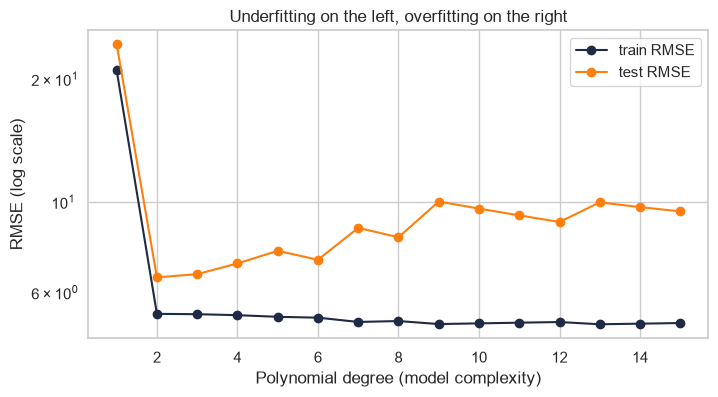

In [7]:
sweep = []
for deg in range(1, 16):
    model = make_pipeline(PolynomialFeatures(deg), StandardScaler(), LinearRegression())
    model.fit(wwr_train.reshape(-1, 1), dem_train)
    sweep.append({
        "degree": deg,
        "train": root_mean_squared_error(dem_train, model.predict(wwr_train.reshape(-1, 1))),
        "test": root_mean_squared_error(dem_test, model.predict(wwr_test.reshape(-1, 1))),
    })
sweep = pd.DataFrame(sweep)

plt.figure(figsize=(8, 4))
plt.plot(sweep["degree"], sweep["train"], "o-", color="#1f2a44", label="train RMSE")
plt.plot(sweep["degree"], sweep["test"], "o-", color="tab:orange", label="test RMSE")
plt.yscale("log")
plt.xlabel("Polynomial degree (model complexity)")
plt.ylabel("RMSE (log scale)")
plt.title("Underfitting on the left, overfitting on the right")
plt.legend()
plt.show()

### The same check on our housing data

We apply the idea to the real task using a **decision tree**, whose complexity is set by `max_depth` (how many yes/no questions it can ask in a row). We use the time-based split from 1.1. Errors are RMSE on `log10(affordability_next)`.

This is only a diagnostic: picking the depth by looking at the test set would leak it into model selection. Later we choose hyperparameters with validation data instead.

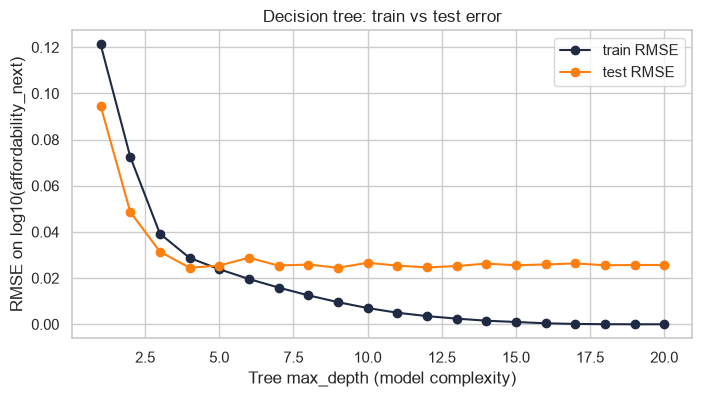

max_depth,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
train,0.1213,0.0726,0.0393,0.0287,0.0238,0.0196,0.0159,0.0126,0.0096,0.0070,0.0050,0.0035,0.0024,0.0015,0.0010,0.0004,0.0001,0.0000,0.0000,0.0000
test,0.0947,0.0487,0.0315,0.0245,0.0254,0.0288,0.0254,0.0259,0.0245,0.0266,0.0254,0.0246,0.0252,0.0263,0.0256,0.0259,0.0264,0.0256,0.0257,0.0257


In [8]:
from sklearn.tree import DecisionTreeRegressor

tree_sweep = []
for depth in range(1, 21):
    tree = DecisionTreeRegressor(max_depth=depth, random_state=42).fit(X_train, y_train)
    tree_sweep.append({
        "max_depth": depth,
        "train": root_mean_squared_error(y_train, tree.predict(X_train)),
        "test": root_mean_squared_error(y_test, tree.predict(X_test)),
    })
tree_sweep = pd.DataFrame(tree_sweep)

plt.figure(figsize=(8, 4))
plt.plot(tree_sweep["max_depth"], tree_sweep["train"], "o-", color="#1f2a44", label="train RMSE")
plt.plot(tree_sweep["max_depth"], tree_sweep["test"], "o-", color="tab:orange", label="test RMSE")
plt.xlabel("Tree max_depth (model complexity)")
plt.ylabel("RMSE on log10(affordability_next)")
plt.title("Decision tree: train vs test error")
plt.legend()
plt.show()

tree_sweep.round(4).set_index("max_depth").T

### What we see

**Synthetic example**
- **Degree 1 (underfitting):** a straight line cannot follow the U-shape. Train and test errors are both high (≈ 21 and 24 kWh/m²/year).
- **Degree 2 (good fit):** follows the true curve. Train and test errors are both low and close (≈ 5 and 6.5).
- **Degree 15 (overfitting):** the lowest training error, but the test error almost doubles (≈ 9.5) and the curve shoots up at the left edge where there are few training points.

**Housing data (decision tree)**
- **Depth 1–3, underfitting:** both errors are high. Test error is even *below* training error here, because the training years include the extreme early values (e.g. South Korea 1978–83) that the test years 2015–2024 do not have.
- **Depth ≈ 4–5, good fit:** test error reaches its minimum, about 0.025 in log10, which is roughly a **6% error** on next year's affordability.
- **Depth > 5, overfitting:** training error keeps falling to **0** (the tree memorises every row by depth ~17), while test error stops improving at ≈ 0.025–0.029. The growing gap between the two curves is the sign of overfitting.

**Takeaway:** judge a model on the test error, and watch the **gap** between training and test error. A training error near zero is a warning, not a success.